# Part 1: Pricing a European option by Monte Carlo

**The question:** can we recover an option price just by simulating the stock, and how far can we trust the number?

A European option is the right place to start, because Black-Scholes gives the exact answer: any error we see comes from the simulation. We price a call and a put, then check three things. The error must shrink at the speed theory predicts, the reported standard error must be honest, and the 95% confidence interval must really contain the exact price about 95% of the time.

**Contract used in all pricing notebooks:** $S_0 = 100$, $K = 100$, $r = 5\%$, $\sigma = 20\%$, $T = 1$ year, no dividends. One random generator with seed 42 is used for the whole notebook, so every number below can be reproduced.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import lognorm

import mc_utils as mc

mc.set_plot_style()
S0, K, r, sigma, T = 100.0, 100.0, 0.05, 0.2, 1.0
rng = np.random.default_rng(42)

## 1. Price the option by simulation

Under the risk-neutral measure the stock follows a geometric Brownian motion. This model has an exact solution, so we can draw $S_T$ directly, without stepping through time and without any discretisation error:

$$S_T = S_0 \exp\Big(\big(r - \tfrac{1}{2}\sigma^2\big)T + \sigma\sqrt{T}\,Z\Big), \qquad Z \sim \mathcal{N}(0,1).$$

The option price is the discounted expected payoff, so we estimate it by the average of $n$ simulated discounted payoffs $Y_i$. By the central limit theorem this average is close to normal, which gives a standard error and a 95% confidence interval:

$$\hat V_n = \frac{1}{n}\sum_{i=1}^{n} Y_i, \qquad \mathrm{SE} = \frac{s_n}{\sqrt{n}}, \qquad \mathrm{CI}_{95\%} = \hat V_n \pm 1.96\,\mathrm{SE}.$$

In [2]:
rows = []
for option in ("call", "put"):
    exact = mc.bs_price(S0, K, r, sigma, T, option)
    for n in (1_000, 10_000, 100_000, 1_000_000):
        res = mc.price_european(S0, K, r, sigma, T, n, option, rng=rng)
        rows.append(
            {
                "option": option,
                "n": n,
                "MC price": res["price"],
                "std error": res["std_error"],
                "CI low": res["ci_low"],
                "CI high": res["ci_high"],
                "Black-Scholes": exact,
                "abs error": abs(res["price"] - exact),
                "CI contains BS": res["ci_low"] <= exact <= res["ci_high"],
            }
        )
pd.DataFrame(rows).round(4)

,option,n,MC price,std error,CI low,CI high,Black-Scholes,abs error,CI contains BS
0,call,1000,9.9120,0.4483,9.0332,10.7907,10.4506,0.5386,True
1,call,10000,10.3887,0.1481,10.0983,10.6790,10.4506,0.0619,True
2,call,100000,10.4260,0.0468,10.3342,10.5178,10.4506,0.0246,True
3,call,1000000,10.4578,0.0147,10.4289,10.4866,10.4506,0.0072,True
4,put,1000,5.3208,0.2668,4.7978,5.8438,5.5735,0.2527,True
5,put,10000,5.5536,0.0866,5.3839,5.7232,5.5735,0.0200,True
6,put,100000,5.5543,0.0273,5.5008,5.6078,5.5735,0.0192,True
7,put,1000000,5.5687,0.0087,5.5517,5.5856,5.5735,0.0049,True


Every interval contains the exact price. With 1,000,000 paths the call is 10.4578 against 10.4506 for Black-Scholes, with a standard error of 0.0147. A single error can be lucky or unlucky, which is why we report the standard error: it falls steadily with $n$.

## 2. Watch the estimate converge

We draw one long sample of 1,000,000 paths and read the running average at growing sample sizes. The band is the 95% confidence interval at each point.

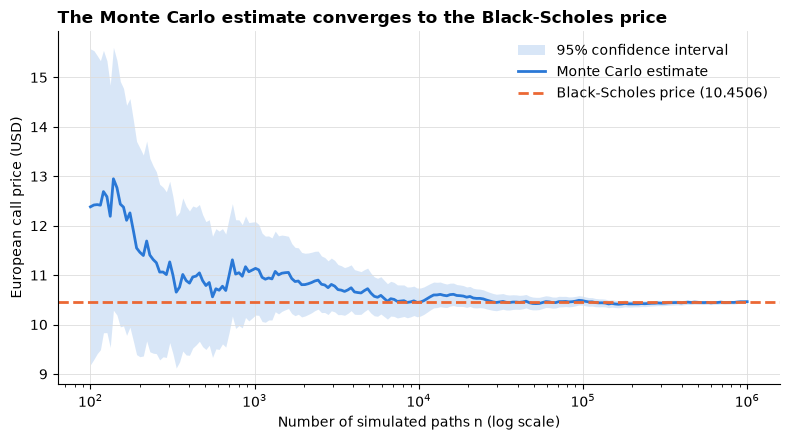

In [3]:
exact = mc.bs_price(S0, K, r, sigma, T, "call")
ns, prices, ses = mc.convergence_curve(S0, K, r, sigma, T, 1_000_000, n_points=200, rng=rng)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.fill_between(
    ns,
    prices - mc.Z_95 * ses,
    prices + mc.Z_95 * ses,
    color=mc.BLUE,
    alpha=0.18,
    linewidth=0,
    label="95% confidence interval",
)
ax.plot(ns, prices, color=mc.BLUE, label="Monte Carlo estimate")
ax.axhline(exact, color=mc.ORANGE, linestyle="--", label=f"Black-Scholes price ({exact:.4f})")
ax.set_xscale("log")
ax.set_xlabel("Number of simulated paths n (log scale)")
ax.set_ylabel("European call price (USD)")
ax.set_title("The Monte Carlo estimate converges to the Black-Scholes price")
ax.legend(loc="upper right")
fig.tight_layout()
fig.savefig("figures/01_convergence.png")
plt.show()

With a few hundred paths the estimate is far off, but the band is wide and says so. As $n$ grows the band narrows around the exact price.

## 3. Check the speed of convergence

Theory says the error falls like $1/\sqrt{n}$: 100 times more paths give 10 times less error. To measure it, we repeat the pricing 300 times at each sample size and compute the root mean squared error (RMSE) against Black-Scholes. On a log-log plot the points should lie on a line of slope $-0.5$. We also compare the RMSE with the standard error reported by the estimator: if the two agree, the reported error can be trusted.

Fitted log-log slope: -0.4983 (theory: -0.5)


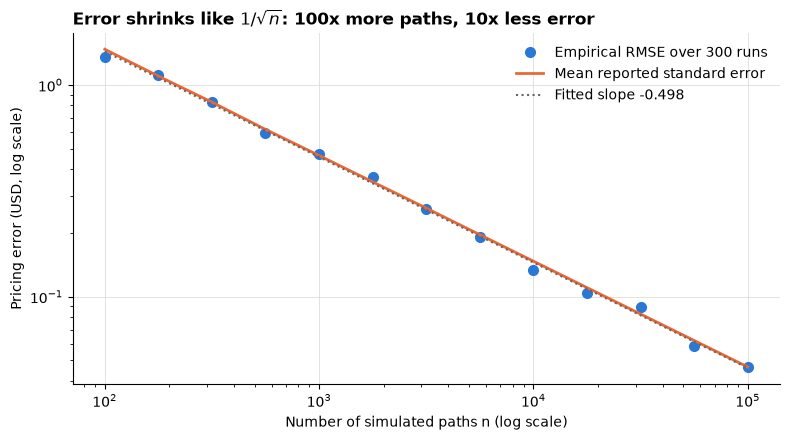

In [4]:
ns = np.unique(np.geomspace(1e2, 1e5, 13).round().astype(int))
n_runs = 300
rmse, mean_se = [], []
for n in ns:
    runs = [mc.price_european(S0, K, r, sigma, T, int(n), rng=rng) for _ in range(n_runs)]
    rmse.append(np.sqrt(np.mean([(run["price"] - exact) ** 2 for run in runs])))
    mean_se.append(np.mean([run["std_error"] for run in runs]))
rmse, mean_se = np.array(rmse), np.array(mean_se)

# Fit log(RMSE) = a + b log(n); theory says b = -0.5.
slope, intercept = np.polyfit(np.log(ns), np.log(rmse), 1)
print(f"Fitted log-log slope: {slope:.4f} (theory: -0.5)")

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(ns, rmse, "o", color=mc.BLUE, markersize=7, label=f"Empirical RMSE over {n_runs} runs")
ax.plot(ns, mean_se, color=mc.ORANGE, label="Mean reported standard error")
ax.plot(
    ns,
    np.exp(intercept) * ns**slope,
    color=mc.GREY,
    linestyle=":",
    linewidth=1.5,
    label=f"Fitted slope {slope:.3f}",
)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Number of simulated paths n (log scale)")
ax.set_ylabel("Pricing error (USD, log scale)")
ax.set_title(r"Error shrinks like $1/\sqrt{n}$: 100x more paths, 10x less error")
ax.legend(loc="upper right")
fig.tight_layout()
fig.savefig("figures/02_error_scaling.png")
plt.show()

The fitted slope is -0.4983, very close to the theoretical -0.5, and the real error matches the reported standard error at every sample size. The standard error is an honest measure of the uncertainty.

## 4. Check the confidence interval

A "95% confidence interval" makes a precise claim: over many independent runs, it should contain the exact price 95% of the time. We test that claim directly on 2,000 runs of 10,000 paths.

In [5]:
runs = [mc.price_european(S0, K, r, sigma, T, 10_000, rng=rng) for _ in range(2_000)]
coverage = np.mean([run["ci_low"] <= exact <= run["ci_high"] for run in runs])
print(f"Share of 95% intervals containing the exact price: {coverage:.2%}")

Share of 95% intervals containing the exact price: 95.10%


The observed coverage of 95.10% is what theory promises, so the intervals are correctly calibrated.

## 5. Look at the simulated world

The left panel shows 40 simulated one-year paths with daily steps. The right panel compares 200,000 simulated values of $S_T$ with the exact lognormal density: $\ln S_T$ is normal with mean $\ln S_0 + (r - \sigma^2/2)T$ and variance $\sigma^2 T$.

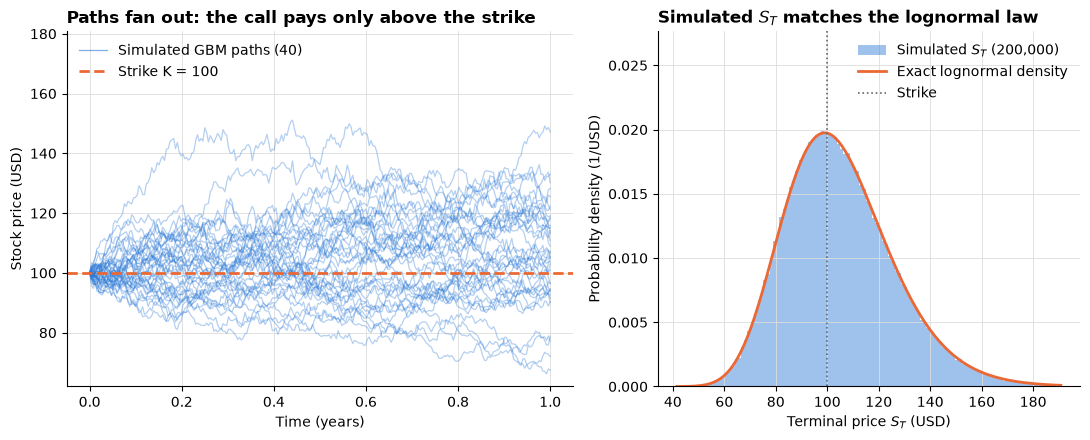

In [6]:
n_steps = 252  # daily steps over one year
paths = mc.simulate_paths(S0, r, sigma, T, 40, n_steps, rng=rng)
times = np.linspace(0.0, T, n_steps + 1)
S_T = mc.simulate_terminal(S0, r, sigma, T, 200_000, rng=rng)
density = lognorm(s=sigma * np.sqrt(T), scale=np.exp(np.log(S0) + (r - 0.5 * sigma**2) * T))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5), gridspec_kw={"width_ratios": [1.2, 1]})
ax1.plot(times, paths.T, color=mc.BLUE, alpha=0.35, linewidth=0.9)
ax1.plot([], [], color=mc.BLUE, alpha=0.6, linewidth=0.9, label="Simulated GBM paths (40)")
ax1.axhline(K, color=mc.ORANGE, linestyle="--", label=f"Strike K = {K:.0f}")
ax1.set_xlabel("Time (years)")
ax1.set_ylabel("Stock price (USD)")
ax1.set_title("Paths fan out: the call pays only above the strike")
ax1.set_ylim(top=paths.max() + 0.35 * (paths.max() - paths.min()))  # room for the legend
ax1.legend(loc="upper left")

x = np.linspace(S_T.min(), np.quantile(S_T, 0.999), 400)
ax2.hist(
    S_T,
    bins=120,
    range=(x[0], x[-1]),
    density=True,
    color=mc.BLUE,
    alpha=0.45,
    label="Simulated $S_T$ (200,000)",
)
ax2.plot(x, density.pdf(x), color=mc.ORANGE, label="Exact lognormal density")
ax2.axvline(K, color=mc.GREY, linestyle=":", linewidth=1.2, label="Strike")
ax2.set_xlabel("Terminal price $S_T$ (USD)")
ax2.set_ylabel("Probability density (1/USD)")
ax2.set_title("Simulated $S_T$ matches the lognormal law")
ax2.set_ylim(0, 1.4 * density.pdf(x).max())  # room for the legend
ax2.legend(loc="upper right")
fig.tight_layout()
fig.savefig("figures/03_paths_and_distribution.png")
plt.show()

The histogram sits exactly on the theoretical density, which confirms the simulation. The paths also show why a call has value: it pays only on the paths that finish above the strike, and it loses nothing more on the others.

## Key takeaways

- Monte Carlo recovers the Black-Scholes price: 10.4578 against 10.4506 with 1,000,000 paths, inside the 95% confidence interval.
- The error falls like $1/\sqrt{n}$ (fitted slope -0.4983), so each extra digit of precision costs 100 times more paths.
- The uncertainty is measured honestly: the reported standard error matches the real error, and 95.10% of the 95% intervals contain the exact price.